## Part 3: Combine SATCAT and ELSET data
#### 1. Combine the content of the 'DS_decayedLEODebris.csv' and 'DS_OMMs.csv' based on the Norad ID

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# read data SATCAT data from csv
decayedLEODebris_df = pd.read_csv('../Data/DS_decayedLEODebris.csv')
decayedLEODebris_df

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD,INCLINATION,APOGEE,PERIGEE,RCS_SIZE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN
2,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN
3,1960-003C,33,DEBRIS,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,93.59,51.29,615.0,285.0,NaN
4,1960-005B,35,ROCKET BODY,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,88.48,64.89,199.0,199.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
25740,1977-065GN,39101,DEBRIS,DELTA 1 DEB,US,1977-07-14,AFETR,2025-02-21,89.81,29.28,286.0,244.0,SMALL
25741,2000-055RC,42360,DEBRIS,NOAA 16 DEB,US,2000-09-21,AFWTR,2025-02-21,92.35,98.81,404.0,375.0,SMALL
25742,2024-140SU,61283,DEBRIS,CZ-6A DEB,PRC,2024-08-06,TSC,2025-02-21,90.32,89.18,305.0,275.0,SMALL
25743,2024-140ADL,61844,DEBRIS,CZ-6A DEB,PRC,2024-08-06,TSC,2025-02-21,90.44,89.24,310.0,282.0,SMALL


In [4]:
# read ELSET data from csv
OMMs_df = pd.read_csv('../Data/DS_OMMs.csv')
OMMs_df

,OBJECT_NAME,OBJECT_ID,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,NORAD_CAT_ID,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,APOAPSIS,PERIAPSIS,OBJECT_TYPE,RCS_SIZE,LAUNCH_DATE,SITE,DECAY_DATE
0,THOR ABLESTAR R/B,1960-003A,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,30,7590,0.000000,0.021256,0.000000,6572.405,88.378,194.270,194.270,ROCKET BODY,NaN,NaN,NaN,1961-08-18
1,SL-3 R/B,1960-005B,16.275237,0.000000,64.8899,44.6976,36.3819,323.6180,35,990,0.000000,0.032711,0.000000,6577.344,88.477,199.209,199.209,ROCKET BODY,NaN,NaN,NaN,1960-07-17
2,SPUTNIK 4 DEB,1960-005D,15.498003,0.019840,64.8899,343.2411,333.4201,27.0840,37,4690,0.000000,0.000390,0.000000,6795.450,92.915,552.139,282.492,DEBRIS,NaN,NaN,NaN,1961-06-30
3,SPUTNIK 4 DEB,1960-005E,15.889090,0.003421,64.8899,302.1218,49.4823,310.6691,38,1500,0.000000,0.006108,0.000000,6683.481,90.628,328.212,282.480,DEBRIS,NaN,NaN,NaN,1960-08-20
4,SPUTNIK 4 DEB,1960-005F,15.825103,0.005994,64.8899,324.0258,55.6628,304.6251,39,1400,0.000000,0.005914,0.000000,6701.485,90.994,363.519,283.181,DEBRIS,NaN,NaN,NaN,1960-09-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24217,CZ-2F DEB,2024-194B,15.683002,0.025785,41.3237,193.5705,294.4302,62.9836,61684,378,0.000489,0.004660,0.000007,6741.901,91.819,537.603,189.929,DEBRIS,LARGE,2024-10-29,JSC,2024-12-21
24218,CZ-6A DEB,2024-140ADL,15.922252,0.002108,89.2435,333.2672,98.2724,262.0952,61844,1983,0.041500,0.096228,0.205730,6674.194,90.439,310.129,281.990,DEBRIS,SMALL,2024-08-06,TSC,2025-02-21
24219,FALCON 9 R/B,2025-022Y,16.475317,0.003106,53.1436,118.6486,5.7660,67.2814,62878,274,0.000110,0.105543,0.000013,6523.980,87.403,166.111,125.580,ROCKET BODY,LARGE,2025-02-01,AFWTR,2025-02-19
24220,VOLGA R/B,2025-026D,14.938871,0.001010,81.9945,220.5351,276.0393,83.9657,62905,3,0.006565,0.000705,0.000000,6963.966,96.393,592.863,578.800,ROCKET BODY,NaN,NaN,NaN,2025-02-05


In [5]:
# merge the two dataframes with outer join
combined_df = pd.merge(decayedLEODebris_df, OMMs_df, on='NORAD_CAT_ID', how='outer')
combined_df

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE_x,DECAY,PERIOD_x,INCLINATION_x,APOGEE,PERIGEE,RCS_SIZE_x,OBJECT_NAME,OBJECT_ID,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD_y,APOAPSIS,PERIAPSIS,OBJECT_TYPE_y,RCS_SIZE_y,LAUNCH_DATE,SITE_y,DECAY_DATE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1959-009B,23,ROCKET BODY,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,89.24,50.27,249.0,225.0,MEDIUM,JUNO II R/B,1959-009B,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,58050.0,0.003007,0.027318,0.019637,6615.232,89.243,249.232,224.963,ROCKET BODY,MEDIUM,1959-10-13,AFETR,1989-07-16
3,1960-002A,28,ROCKET BODY,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,87.80,48.34,168.0,163.0,LARGE,THOR ABLE R/B,1960-002A,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,67681.0,0.001474,0.208109,0.000057,6543.639,87.798,167.878,163.130,ROCKET BODY,LARGE,1960-04-01,AFETR,1991-07-03
4,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN,THOR ABLESTAR R/B,1960-003A,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,7590.0,0.000000,0.021256,0.000000,6572.405,88.378,194.270,194.270,ROCKET BODY,NaN,NaN,NaN,1961-08-18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25740,2024-248C,62408,ROCKET BODY,ELECTRON R/B,US,2024-12-21,RLLC,2024-12-29,87.73,97.51,196.0,128.0,MEDIUM,ELECTRON R/B,2024-248C,16.413207,0.005214,97.5072,319.3027,205.7092,203.0096,129.0,0.000478,0.284337,0.000002,6540.429,87.734,196.397,128.191,ROCKET BODY,MEDIUM,2024-12-21,RLLC,2024-12-29
25741,2024-200B,62608,DEBRIS,DRAGON CRS-31 DEB,US,2024-11-05,AFETR,2025-01-29,87.80,51.62,170.0,162.0,LARGE,DRAGON CRS-31 DEB,2024-200B,16.400532,0.000599,51.6226,259.7984,314.7115,89.5839,247.0,0.000395,0.055156,0.000012,6543.798,87.802,169.583,161.743,DEBRIS,LARGE,2024-11-05,AFETR,2025-01-29
25742,2025-022Y,62878,ROCKET BODY,FALCON 9 R/B,US,2025-02-01,AFWTR,2025-02-19,87.40,53.14,166.0,126.0,LARGE,FALCON 9 R/B,2025-022Y,16.475317,0.003106,53.1436,118.6486,5.7660,67.2814,274.0,0.000110,0.105543,0.000013,6523.980,87.403,166.111,125.580,ROCKET BODY,LARGE,2025-02-01,AFWTR,2025-02-19
25743,2025-026D,62905,ROCKET BODY,VOLGA R/B,CIS,2025-02-05,PKMTR,2025-02-05,96.39,81.99,593.0,579.0,NaN,VOLGA R/B,2025-026D,14.938871,0.001010,81.9945,220.5351,276.0393,83.9657,3.0,0.006565,0.000705,0.000000,6963.966,96.393,592.863,578.800,ROCKET BODY,NaN,NaN,NaN,2025-02-05


In [6]:
# drop objects from DS_WrongIDs.csv
wrongIDs_df = pd.read_csv('../Data/DS_WrongIDs.csv')
combined_df = combined_df[~combined_df['NORAD_CAT_ID'].isin(wrongIDs_df['NORAD_CAT_ID'])]

#### 2. Examine the objects without OMM data to see if they can be dropped unproblematically

In [8]:
# check if Object ID column can be used as identifyer for present OMM data
print(OMMs_df['OBJECT_ID'].isnull().sum())

0


In [9]:
# extract rows whithout OMM data
missing_OMMs_df = combined_df[combined_df['OBJECT_ID'].isnull()].copy()
missing_OMMs_df

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE_x,DECAY,PERIOD_x,INCLINATION_x,APOGEE,PERIGEE,RCS_SIZE_x,OBJECT_NAME,OBJECT_ID,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD_y,APOAPSIS,PERIAPSIS,OBJECT_TYPE_y,RCS_SIZE_y,LAUNCH_DATE,SITE_y,DECAY_DATE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,1962-019B,296,ROCKET BODY,ATLAS D 7 R/B,US,1962-05-24,AFETR,1962-05-25,88.80,32.50,292.0,138.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
280,1963-036E,666,DEBRIS,ATLAS AGENA D DEB,US,1963-09-06,AFWTR,1963-09-10,87.90,94.30,171.0,170.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
296,1963-050C,709,DEBRIS,SL-7 DEB,CIS,1963-12-13,KYMTR,1964-01-03,89.60,48.90,284.0,232.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21327,2013-011B,39121,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-03-19,AFETR,2014-11-22,92.28,21.40,644.0,129.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21355,2013-050B,39257,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-09-18,AFETR,2015-02-08,93.14,19.23,753.0,103.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21372,2013-055X,39289,DEBRIS,FALCON 9 DEB,US,2013-09-29,AFWTR,2013-10-13,92.94,80.99,534.0,302.0,SMALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21788,2016-042N,41638,DEBRIS,CZ-7 DEB,PRC,2016-06-25,WSC,2016-06-29,88.49,40.82,264.0,136.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# check how often which object type occurs in the missing TLE data and overall data
combined_type_counts = combined_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
missing_type_counts = missing_OMMs_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
print("Combined type counts: ", combined_type_counts, "\n")
print("Missing type counts: ", missing_type_counts)

Combined type counts:  OBJECT_TYPE_x
DEBRIS         84.312177
ROCKET BODY    15.687823
Name: proportion, dtype: float64 

Missing type counts:  OBJECT_TYPE_x
DEBRIS         90.337284
ROCKET BODY     9.662716
Name: proportion, dtype: float64


In [11]:
# check size of objects
combined_size_counts = (combined_df['RCS_SIZE_x'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
missing_size_counts = (missing_OMMs_df['RCS_SIZE_x'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
print("Combined size counts: ", combined_size_counts, "\n")
print("Missing size counts: ", missing_size_counts)

Combined size counts:  RCS_SIZE_x
SMALL     64.019528
MEDIUM    19.571467
LARGE     16.409005
Name: proportion, dtype: float64 

Missing size counts:  RCS_SIZE_x
SMALL     54.545455
MEDIUM    19.008264
LARGE     26.446281
Name: proportion, dtype: float64


Missing_TLEs_df 'LAUNCH' column datatype:  datetime64[ns]
combined_df 'LAUNCH' column datatype:  datetime64[ns]


/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/143057514.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df['LAUNCH'] = pd.to_datetime(combined_df['LAUNCH'])


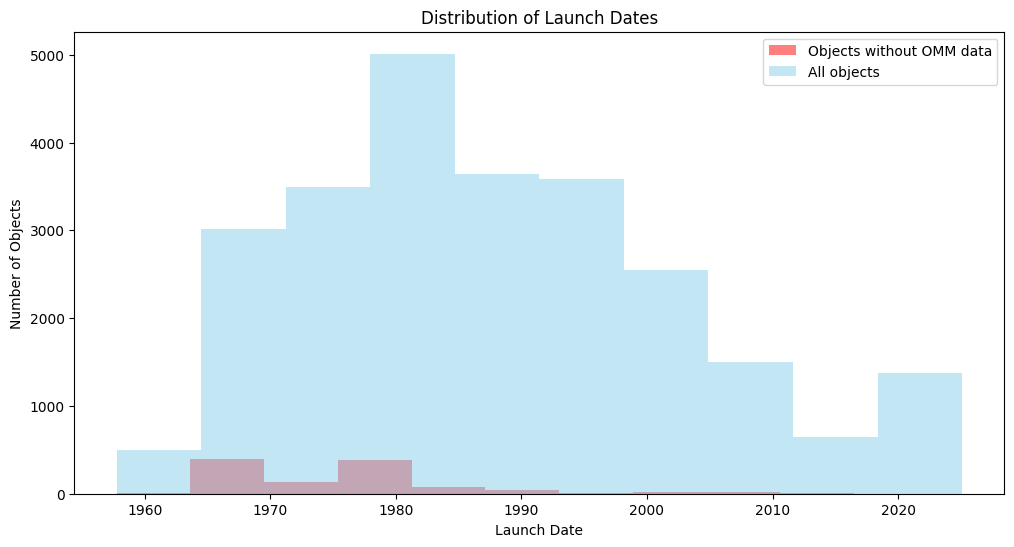

In [12]:
# display launch dates on a timeline
# convert the launch date to a datetime object
missing_OMMs_df['LAUNCH'] = pd.to_datetime(missing_OMMs_df['LAUNCH'])
combined_df['LAUNCH'] = pd.to_datetime(combined_df['LAUNCH'])

# show types of launch and decay date columns
print("Missing_TLEs_df 'LAUNCH' column datatype: ", missing_OMMs_df['LAUNCH'].dtype)
print("combined_df 'LAUNCH' column datatype: ", combined_df['LAUNCH'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_OMMs_df['LAUNCH'], bins=10, color='red', alpha=0.5, label='Objects without OMM data')
plt.hist(combined_df['LAUNCH'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Launch Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Launch Dates')
plt.legend()
plt.show()

Missing_OMMs_df 'DECAY' column datatype:  datetime64[ns]
combined_df 'DECAY' column datatype:  datetime64[ns]


/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/1652195854.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df['DECAY'] = pd.to_datetime(combined_df['DECAY'])


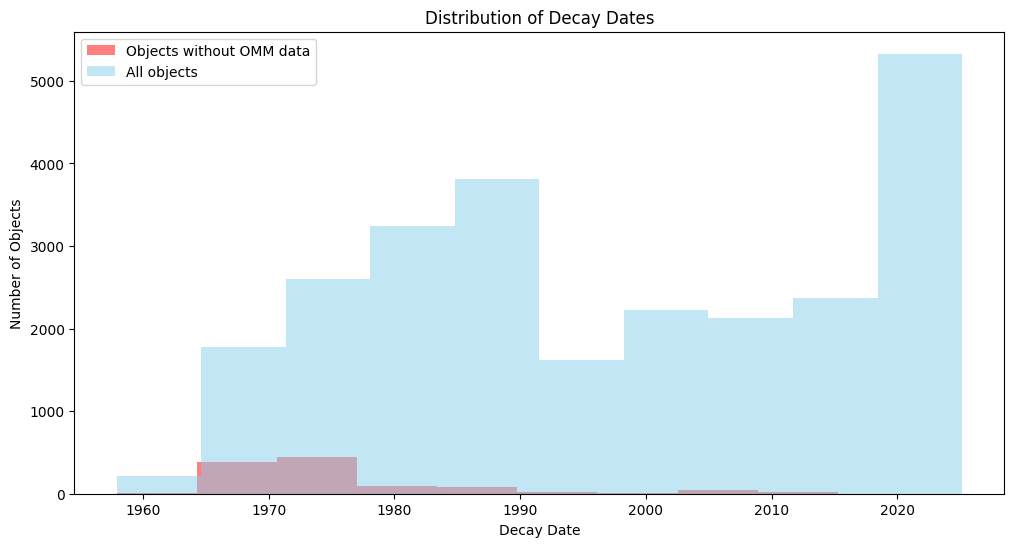

In [13]:
# display decay dates on a timeline
# convert the decay date to a datetime object
missing_OMMs_df['DECAY'] = pd.to_datetime(missing_OMMs_df['DECAY'])
combined_df['DECAY'] = pd.to_datetime(combined_df['DECAY'])

# check datatypes of decay date columns
print("Missing_OMMs_df 'DECAY' column datatype: ", missing_OMMs_df['DECAY'].dtype)
print("combined_df 'DECAY' column datatype: ", combined_df['DECAY'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_OMMs_df['DECAY'], bins=10, color='red', alpha=0.5, label='Objects without OMM data')
plt.hist(combined_df['DECAY'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Decay Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Decay Dates')
plt.legend()
plt.show()

In [14]:
# Calculate Lifetime of the Objects since the distribution of launch and decay dates is similar and suggests that maybe all objects had a too short lifetime to record OMMs
missing_OMMs_df.insert(8, 'LIFETIME', missing_OMMs_df['DECAY'] - missing_OMMs_df['LAUNCH'])
# Calculate Lifetime of all objects
combined_df.insert(8, 'LIFETIME', combined_df['DECAY'] - combined_df['LAUNCH'])

In [15]:
# review statistics of the lifetime columns
print("Lifetime statistics over all objects:")
print(combined_df['LIFETIME'].describe(), "\n")
print("Lifetime statistics over objects without OMM data:")
print(missing_OMMs_df['LIFETIME'].describe())

Lifetime statistics over all objects:
count                           25319
mean     3487 days 08:27:19.116868736
std      4764 days 07:31:08.166407936
min                   0 days 00:00:00
25%                  31 days 00:00:00
50%                 884 days 00:00:00
75%                5709 days 12:00:00
max               23115 days 00:00:00
Name: LIFETIME, dtype: object 

Lifetime statistics over objects without OMM data:
count                            1097
mean      451 days 04:34:20.893345488
std      1586 days 21:50:40.136507376
min                   0 days 00:00:00
25%                   5 days 00:00:00
50%                  14 days 00:00:00
75%                  22 days 00:00:00
max               12950 days 00:00:00
Name: LIFETIME, dtype: object


##### Objects without OMM data can be dropped unproblematically since they mostly had a relatively short lifetime and thus the explaination seems plausible that there was no chance to record OMMs.

In [16]:
# show objects count
print("Number of all objects: ", len(combined_df))
# drop objects without OMM data
combined_df.dropna(subset=['OBJECT_ID'], inplace=True)
# show number of remaining objects
print("Remaining objects: ", len(combined_df))

Number of all objects:  25319
Remaining objects:  24222


/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/4285011847.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.dropna(subset=['OBJECT_ID'], inplace=True)


#### 3. Drop not needed columns: Check duplicate columns to see if they contain the same values.  If they do not, check why and which one makes more sense to drop. 

In [17]:
# compare columns with same content to check if they contain the same values
# List of column names to compare
columns_to_compare = [
    'OBJECT_TYPE', 'SITE', 'PERIOD', 'INCLINATION', 'RCS_SIZE'
]

# Initialize a dictionary to store the columns that are not equal
unequal_columns = {}

# Loop through the columns and check for inequality
for col in columns_to_compare:
    are_equal = combined_df[f'{col}_x'].equals(combined_df[f'{col}_y'])
    print(f"{col}: {are_equal}")
    if not are_equal:
        unequal_columns[f'{col}_x'] = combined_df[f'{col}_x']
        unequal_columns[f'{col}_y'] = combined_df[f'{col}_y']

# Create a DataFrame out of the unequal columns
unequal_df = pd.DataFrame(unequal_columns)

print("\nComparison of unequal columns side by side:")
unequal_df

OBJECT_TYPE: False
SITE: False
PERIOD: False
INCLINATION: False
RCS_SIZE: False

Comparison of unequal columns side by side:


,OBJECT_TYPE_x,OBJECT_TYPE_y,SITE_x,SITE_y,PERIOD_x,PERIOD_y,INCLINATION_x,INCLINATION_y,RCS_SIZE_x,RCS_SIZE_y
2,ROCKET BODY,ROCKET BODY,AFETR,AFETR,89.24,89.243,50.27,50.2674,MEDIUM,MEDIUM
3,ROCKET BODY,ROCKET BODY,AFETR,AFETR,87.80,87.798,48.34,48.3426,LARGE,LARGE
4,ROCKET BODY,ROCKET BODY,AFETR,NaN,88.38,88.378,51.25,51.2500,NaN,NaN
6,ROCKET BODY,ROCKET BODY,TTMTR,NaN,88.48,88.477,64.89,64.8899,NaN,NaN
7,DEBRIS,DEBRIS,TTMTR,NaN,92.92,92.915,64.89,64.8899,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
25740,ROCKET BODY,ROCKET BODY,RLLC,RLLC,87.73,87.734,97.51,97.5072,MEDIUM,MEDIUM
25741,DEBRIS,DEBRIS,AFETR,AFETR,87.80,87.802,51.62,51.6226,LARGE,LARGE
25742,ROCKET BODY,ROCKET BODY,AFWTR,AFWTR,87.40,87.403,53.14,53.1436,LARGE,LARGE
25743,ROCKET BODY,ROCKET BODY,PKMTR,NaN,96.39,96.393,81.99,81.9945,NaN,NaN


In [18]:
# check null values
# site
print("SITE_x: ", unequal_df['SITE_x'].isnull().sum())
print("SITE_y: ", unequal_df['SITE_y'].isnull().sum())
# period
print("PERIOD_x: ", unequal_df['PERIOD_x'].isnull().sum())
print("PERIOD_y: ", unequal_df['PERIOD_y'].isnull().sum())
# inclination
print("INCLINATION_x: ", unequal_df['INCLINATION_x'].isnull().sum())
print("INCLINATION_y: ", unequal_df['INCLINATION_y'].isnull().sum())
# RCS_SIZE
print("RCS_SIZE_x: ", unequal_df['RCS_SIZE_x'].isnull().sum())
print("RCS_SIZE_y: ", unequal_df['RCS_SIZE_y'].isnull().sum())


SITE_x:  0
SITE_y:  8259
PERIOD_x:  0
PERIOD_y:  0
INCLINATION_x:  0
INCLINATION_y:  0
RCS_SIZE_x:  5908
RCS_SIZE_y:  8818


In [19]:
# delete columns 
combined_df.drop(columns=[
    'OBJECT_TYPE_y', # y and y columns are the same
    'SITE_y', # x has no null values
    'PERIOD_x', # y has more decimal places
    'INCLINATION_x', # y has more decimal places 
    'RCS_SIZE_y', 'RCS_SIZE_x' # both have too many null values
    ], inplace=True)

# rename columns
combined_df.rename(columns={
    'OBJECT_TYPE_x': 'OBJECT_TYPE',
    'SITE_x': 'SITE',
    'PERIOD_y': 'PERIOD',
    'INCLINATION_y': 'INCLINATION',
    'RCS_SIZE_x': 'RCS_SIZE'
}, inplace=True)

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/1231852088.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.drop(columns=[
/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/1231852088.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.rename(columns={


In [20]:
# check datatypes of launch and decay columns
print("LAUNCH: ", combined_df['LAUNCH'].dtype)
print("DECAY: ", combined_df['DECAY'].dtype)
print("LAUNCH_DATE: ", combined_df['LAUNCH_DATE'].dtype)
print("DECAY_DATE: ", combined_df['DECAY_DATE'].dtype)

LAUNCH:  datetime64[ns]
DECAY:  datetime64[ns]
LAUNCH_DATE:  object
DECAY_DATE:  object


In [21]:
# convert launch and decay columns to datetime
combined_df['LAUNCH_DATE'] = pd.to_datetime(combined_df['LAUNCH'])
combined_df['DECAY_DATE'] = pd.to_datetime(combined_df['DECAY'])

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/2483249257.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df['LAUNCH_DATE'] = pd.to_datetime(combined_df['LAUNCH'])
/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/2483249257.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df['DECAY_DATE'] = pd.to_datetime(combined_df['DECAY'])


In [22]:
# compare launch and decay columns 
print("Launch: ", combined_df['LAUNCH_DATE'].equals(combined_df['LAUNCH']))
print("Decay: ", combined_df['DECAY_DATE'].equals(combined_df['DECAY']))

Launch:  True
Decay:  True


In [23]:
# drop launch and decay columns
combined_df.drop(columns=['LAUNCH_DATE', 'DECAY_DATE'], inplace=True)

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/1187741296.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.drop(columns=['LAUNCH_DATE', 'DECAY_DATE'], inplace=True)


In [24]:
# compare Object ID and International Designator
print(combined_df['OBJECT_ID'].equals(combined_df['INTLDES']))

False


In [25]:
# show rows where Object ID and International Designator are not equal with only the relevant columns
combined_df[combined_df['OBJECT_ID'] != combined_df['INTLDES']][['OBJECT_ID', 'INTLDES']]

,OBJECT_ID,INTLDES
2331,1966-025F,1966-063F
5871,1976-124C,1976-037AB
6005,1976-124D,1976-124C
6008,1976-124E,1976-124D
6014,1976-124F,1976-124E
6015,1976-124G,1976-124F
6016,1976-124H,1976-124G
6017,1976-124J,1976-124H
6018,1976-124K,1976-124J
6019,1976-124L,1976-124K


In [26]:
# the differences seem to come from the fact that ELSET data (OBJECT_ID) gets updated more frequently and reflects fragmentations and reassignments 
# the SATCAT data (INTLDES) retains historical launch assignments 
# therefore: keep OBJECT_ID and drop INTLDES
combined_df.drop(columns=['INTLDES'], inplace=True)
# rename to INTLDES since it describes the data better
combined_df.rename(columns={'OBJECT_ID': 'INTLDES'}, inplace=True)

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/3764030013.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.drop(columns=['INTLDES'], inplace=True)
/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/3764030013.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.rename(columns={'OBJECT_ID': 'INTLDES'}, inplace=True)


In [27]:
# compare SATNAME and OBJECT_NAME
print(combined_df['SATNAME'].equals(combined_df['OBJECT_NAME']))

True


In [28]:
# drop OBJECT_NAME
combined_df.drop(columns=['OBJECT_NAME'], inplace=True)

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/374459990.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.drop(columns=['OBJECT_NAME'], inplace=True)


In [29]:
# compare PERIGEE/APOGEE with PERIAPSIS and APOAPSIS
combined_df[['PERIGEE', 'PERIAPSIS', 'APOGEE', 'APOAPSIS']]

,PERIGEE,PERIAPSIS,APOGEE,APOAPSIS
2,225.0,224.963,249.0,249.232
3,163.0,163.130,168.0,167.878
4,194.0,194.270,194.0,194.270
6,199.0,199.209,199.0,199.209
7,282.0,282.492,552.0,552.139
...,...,...,...,...
25740,128.0,128.191,196.0,196.397
25741,162.0,161.743,170.0,169.583
25742,126.0,125.580,166.0,166.111
25743,579.0,578.800,593.0,592.863


In [30]:
# drop PERIGEE and APOGEE since PERIAPOSIS and APOAPSIS are more accurate
combined_df.drop(columns=['PERIGEE', 'APOGEE'], inplace=True)

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_54866/426623646.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df.drop(columns=['PERIGEE', 'APOGEE'], inplace=True)


In [31]:
# change order of columns
combined_df = combined_df[['NORAD_CAT_ID', 'INTLDES', 'SATNAME', 'OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 'DECAY', # information with no relevance for lifetime
                           'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD', # features - OMM information
                           'LIFETIME']] # label
combined_df

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,DECAY,PERIAPSIS,APOAPSIS,ARG_OF_PERICENTER,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,LIFETIME
2,23,1959-009B,JUNO II R/B,ROCKET BODY,US,AFETR,1959-10-13,1989-07-16,224.963,249.232,32.5712,16.135613,0.001834,50.2674,226.9734,327.5638,58050.0,0.003007,0.027318,0.019637,6615.232,89.243,10869 days
3,28,1960-002A,THOR ABLE R/B,ROCKET BODY,US,AFETR,1960-04-01,1991-07-03,163.130,167.878,333.1829,16.401144,0.000363,48.3426,203.3369,26.9220,67681.0,0.001474,0.208109,0.000057,6543.639,87.798,11415 days
4,30,1960-003A,THOR ABLESTAR R/B,ROCKET BODY,US,AFETR,1960-04-13,1961-08-18,194.270,194.270,331.9473,16.293583,0.000000,51.2500,356.4892,28.0526,7590.0,0.000000,0.021256,0.000000,6572.405,88.378,492 days
6,35,1960-005B,SL-3 R/B,ROCKET BODY,CIS,TTMTR,1960-05-15,1960-07-17,199.209,199.209,36.3819,16.275237,0.000000,64.8899,44.6976,323.6180,990.0,0.000000,0.032711,0.000000,6577.344,88.477,63 days
7,37,1960-005D,SPUTNIK 4 DEB,DEBRIS,CIS,TTMTR,1960-05-15,1961-06-30,282.492,552.139,333.4201,15.498003,0.019840,64.8899,343.2411,27.0840,4690.0,0.000000,0.000390,0.000000,6795.450,92.915,411 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25740,62408,2024-248C,ELECTRON R/B,ROCKET BODY,US,RLLC,2024-12-21,2024-12-29,128.191,196.397,205.7092,16.413207,0.005214,97.5072,319.3027,203.0096,129.0,0.000478,0.284337,0.000002,6540.429,87.734,8 days
25741,62608,2024-200B,DRAGON CRS-31 DEB,DEBRIS,US,AFETR,2024-11-05,2025-01-29,161.743,169.583,314.7115,16.400532,0.000599,51.6226,259.7984,89.5839,247.0,0.000395,0.055156,0.000012,6543.798,87.802,85 days
25742,62878,2025-022Y,FALCON 9 R/B,ROCKET BODY,US,AFWTR,2025-02-01,2025-02-19,125.580,166.111,5.7660,16.475317,0.003106,53.1436,118.6486,67.2814,274.0,0.000110,0.105543,0.000013,6523.980,87.403,18 days
25743,62905,2025-026D,VOLGA R/B,ROCKET BODY,CIS,PKMTR,2025-02-05,2025-02-05,578.800,592.863,276.0393,14.938871,0.001010,81.9945,220.5351,83.9657,3.0,0.006565,0.000705,0.000000,6963.966,96.393,0 days


In [32]:
# save to csv
combined_df.to_csv('../Data/DS_combined.csv', index=False)